In [1]:
# !pip install torch torchvision librosa soundfile scipy scikit-learn pandas numpy matplotlib seaborn tqdm
import os, zipfile, urllib.request, random
from pathlib import Path
import numpy as np
import pandas as pd
import librosa, librosa.display
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal as sp_signal
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

import warnings
warnings.filterwarnings("ignore")

SEED = 42
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if device.type == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(f"  GPU: {torch.cuda.get_device_name(0)}, "
          f"VRAM: {p.total_memory/1e9:.1f} GB, CUDA: {torch.version.cuda}")

Device: cuda
  GPU: NVIDIA GeForce MX250, VRAM: 2.1 GB, CUDA: 12.6


In [2]:
URL      = "https://github.com/karolpiczak/ESC-50/archive/refs/heads/master.zip"
ZIP_PATH = Path("esc50.zip")
DATA_DIR = Path("ESC-50-master")

if not DATA_DIR.exists():
    if not ZIP_PATH.exists():
        print("Скачиваем архив (~600 МБ)...")
        def _progress(bn, bs, ts):
            d = bn * bs
            if ts > 0 and bn % 200 == 0:
                print(f"\r  {d/1e6:6.1f} / {ts/1e6:.0f} МБ  ({100*d/ts:5.1f}%)",
                      end="", flush=True)
        urllib.request.urlretrieve(URL, ZIP_PATH, reporthook=_progress)
        print("\n  готово.")
    print("Распаковываем...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        with tqdm(total=len(zf.infolist()), desc="  extract", unit="file") as pbar:
            for m in zf.infolist():
                zf.extract(m, "."); pbar.update(1)
else:
    print(f"Каталог {DATA_DIR} уже существует.")

assert (DATA_DIR / "meta" / "esc50.csv").exists()
print(f"WAV-файлов: {len(list((DATA_DIR / 'audio').glob('*.wav')))}")

Каталог ESC-50-master уже существует.
WAV-файлов: 2000


In [3]:
meta  = pd.read_csv(DATA_DIR / "meta" / "esc50.csv")
esc10 = meta[meta["esc10"] == True].reset_index(drop=True)

le = LabelEncoder()
esc10["label"] = le.fit_transform(esc10["category"])

y_all     = esc10["label"].values.astype(np.int64)
folds_arr = esc10["fold"].values
classes   = list(le.classes_)

print(f"Размер ESC-10: {esc10.shape}")
print(esc10["category"].value_counts().to_string())
print(f"\nКлассы: {classes}")

Размер ESC-10: (400, 8)
category
dog               40
chainsaw          40
crackling_fire    40
helicopter        40
rain              40
crying_baby       40
clock_tick        40
sneezing          40
rooster           40
sea_waves         40

Классы: ['chainsaw', 'clock_tick', 'crackling_fire', 'crying_baby', 'dog', 'helicopter', 'rain', 'rooster', 'sea_waves', 'sneezing']


sr=44100, duration=5.00s


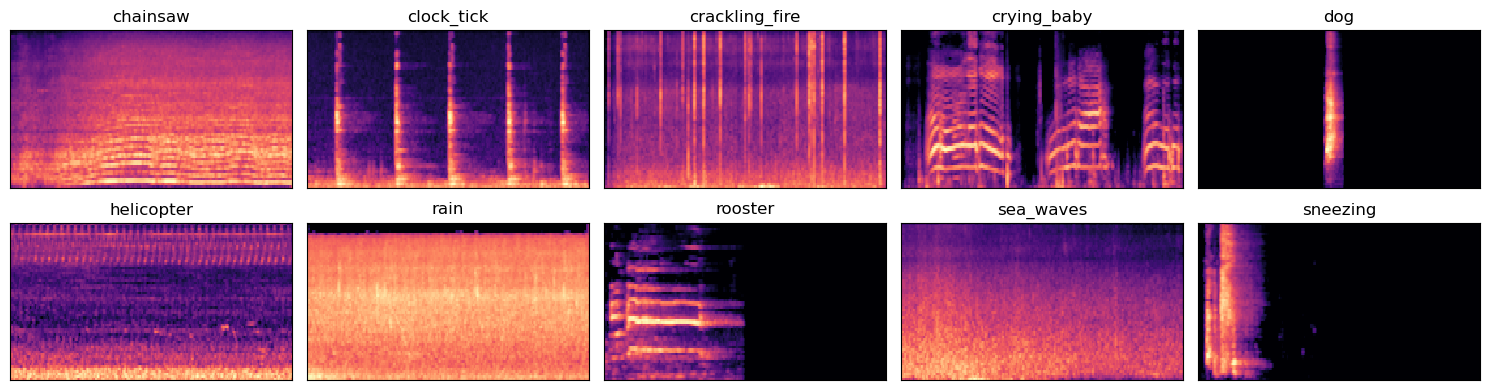

In [4]:
y, sr = librosa.load(DATA_DIR / "audio" / esc10.loc[0, "filename"], sr=None)
print(f"sr={sr}, duration={len(y)/sr:.2f}s")

fig, axes = plt.subplots(2, 5, figsize=(15, 4))
for ax, cat in zip(axes.ravel(), classes):
    row = esc10[esc10["category"] == cat].iloc[0]
    y, sr = librosa.load(DATA_DIR / "audio" / row["filename"], sr=22050)
    S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=64)
    librosa.display.specshow(librosa.power_to_db(S), sr=sr, ax=ax, cmap="magma")
    ax.set_title(cat); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

In [5]:
SR, N_FFT, HOP = 22050, 2048, 512
TARGET_FRAMES  = 216
N_MELS         = 128

# ---------- Предобработка первичного сигнала ----------
def apply_preprocessing(y, sr=SR, preemphasis=0.97, bp_low=100, bp_high=8000):
    """Pre-emphasis + band-pass. Применяется ДО вычисления спектрограмм."""
    y_pe = np.append(y[0], y[1:] - preemphasis * y[:-1])
    sos  = sp_signal.butter(4, [bp_low, bp_high], btype="band", fs=sr, output="sos")
    y_bp = sp_signal.sosfiltfilt(sos, y_pe)
    return y_bp.astype(np.float32)


def trim_silence(y, top_db=20):
    _, (s, e) = librosa.effects.trim(y, top_db=top_db)
    return y[s:e]


def load_preprocessed(path):
    y, _ = librosa.load(path, sr=SR)
    y = apply_preprocessing(y)
    y = trim_silence(y)
    return y


def _pad_or_crop(S, target=TARGET_FRAMES, fill=None):
    """S: (freq, time). Возвращает (freq, target)."""
    if fill is None:
        fill = S.min()
    if S.shape[1] < target:
        S = np.pad(S, ((0, 0), (0, target - S.shape[1])),
                   mode="constant", constant_values=fill)
    else:
        S = S[:, :target]
    return S


# ---------- MFCC-статистики для sklearn ----------
def mfcc_stats(path, n_mfcc=40):
    y = load_preprocessed(path)
    if len(y) < N_FFT:
        y = np.pad(y, (0, N_FFT - len(y)))
    m  = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=n_mfcc, n_fft=N_FFT, hop_length=HOP)
    d1 = librosa.feature.delta(m, order=1)
    return np.concatenate([m.mean(1), m.std(1), d1.mean(1), d1.std(1)])


# ---------- MFCC-последовательности для BiLSTM ----------
def mfcc_seq(path, n_mfcc=40):
    y = load_preprocessed(path)
    m = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=n_mfcc, hop_length=HOP)
    m = _pad_or_crop(m, fill=0.0)
    return m.T                                           # (T, F)


# ---------- Спектрограмма 1: log-mel ----------
def logmel(path):
    y = load_preprocessed(path)
    S = librosa.feature.melspectrogram(y=y, sr=SR, n_mels=N_MELS,
                                       n_fft=N_FFT, hop_length=HOP)
    S = librosa.power_to_db(S, ref=np.max)
    S = _pad_or_crop(S, fill=S.min())
    return S.T                                           # (T, n_mels)


# ---------- Спектрограмма 2: CQT ----------
def cqt_spec(path):
    y = load_preprocessed(path)
    C = librosa.cqt(y, sr=SR, hop_length=HOP,
                    n_bins=84, bins_per_octave=12,
                    fmin=librosa.note_to_hz("C1"))
    C = librosa.amplitude_to_db(np.abs(C), ref=np.max)   # (84, T)
    C = _pad_or_crop(C, fill=C.min())
    return C.T                                           # (T, 84)


# ---------- Спектрограмма 3: PCEN-mel ----------
def pcen_spec(path):
    y = load_preprocessed(path)
    S = librosa.feature.melspectrogram(y=y, sr=SR, n_mels=N_MELS,
                                       n_fft=N_FFT, hop_length=HOP)  # power
    P = librosa.pcen(S, sr=SR, hop_length=HOP)           # (n_mels, T), ~[0, 1]
    # Логарифм для стабилизации больших динамических диапазонов
    P = np.log(P + 1e-6)
    P = _pad_or_crop(P, fill=P.min())
    return P.T                                           # (T, n_mels)


# ---------- Извлечение всего ----------
def stack_3d(fn, desc):
    arr = np.stack([fn(DATA_DIR / "audio" / f) for f in tqdm(esc10["filename"], desc=desc)])
    return arr.astype(np.float32)


def normalize_spec_4d(X):
    """X: (N, T, F) -> (N, 1, T, F), per-sample mean=0, std=1."""
    X = X[:, None, :, :].astype(np.float32)
    mu  = X.mean(axis=(1, 2, 3), keepdims=True)
    sig = X.std(axis=(1, 2, 3), keepdims=True) + 1e-6
    return (X - mu) / sig


print("Извлекаем MFCC-статистики (с фильтрами)...")
X_mfcc = stack_3d(mfcc_stats, "  mfcc-stats")
print(f"  {X_mfcc.shape}")

print("\nИзвлекаем MFCC-последовательности (с фильтрами)...")
X_seq = stack_3d(mfcc_seq, "  mfcc-seq")
print(f"  {X_seq.shape}")

print("\nИзвлекаем log-mel...")
X_mel = normalize_spec_4d(stack_3d(logmel, "  log-mel"))
print(f"  {X_mel.shape}")

print("\nИзвлекаем CQT...")
X_cqt = normalize_spec_4d(stack_3d(cqt_spec, "  cqt"))
print(f"  {X_cqt.shape}")

print("\nИзвлекаем PCEN-mel...")
X_pcen = normalize_spec_4d(stack_3d(pcen_spec, "  pcen"))
print(f"  {X_pcen.shape}")

np.savez_compressed("esc10_features_v2.npz",
                    X_mfcc=X_mfcc, X_seq=X_seq,
                    X_mel=X_mel, X_cqt=X_cqt, X_pcen=X_pcen,
                    y=y_all, folds=folds_arr)
print("\nСохранено: esc10_features_v2.npz")

Извлекаем MFCC-статистики (с фильтрами)...


  mfcc-stats:   0%|          | 0/400 [00:00<?, ?it/s]

  (400, 160)

Извлекаем MFCC-последовательности (с фильтрами)...


  mfcc-seq:   0%|          | 0/400 [00:00<?, ?it/s]

  (400, 216, 40)

Извлекаем log-mel...


  log-mel:   0%|          | 0/400 [00:00<?, ?it/s]

  (400, 1, 216, 128)

Извлекаем CQT...


  cqt:   0%|          | 0/400 [00:00<?, ?it/s]

  (400, 1, 216, 84)

Извлекаем PCEN-mel...


  pcen:   0%|          | 0/400 [00:00<?, ?it/s]

  (400, 1, 216, 128)

Сохранено: esc10_features_v2.npz


In [6]:
folds = [(np.where(folds_arr != f)[0], np.where(folds_arr == f)[0])
         for f in range(1, 6)]
results = []

def evaluate(y_true, y_pred, name):
    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred, average="macro")
    print(f"{name:32s}  acc={acc:.4f}  macro-F1={f1:.4f}")
    r = {"model": name, "acc": acc, "f1": f1,
         "y_true": np.array(y_true), "y_pred": np.array(y_pred)}
    results.append(r)
    return r

In [7]:
def run_sklearn(make_clf, X, y, name, scale=True):
    all_true, all_pred = [], []
    for tr, te in tqdm(folds, desc=name):
        Xtr, Xte = X[tr], X[te]
        if scale:
            sc = StandardScaler().fit(Xtr)
            Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)
        clf = make_clf()
        clf.fit(Xtr, y[tr])
        all_true.extend(y[te]); all_pred.extend(clf.predict(Xte))
    return evaluate(all_true, all_pred, name)

run_sklearn(
    lambda: LogisticRegression(max_iter=2000, C=1.0, multi_class="multinomial"),
    X_mfcc, y_all, "LogReg + MFCC (filt.)"
)
run_sklearn(
    lambda: SVC(kernel="rbf", C=10, gamma="scale"),
    X_mfcc, y_all, "SVM-RBF + MFCC (filt.)"
)
run_sklearn(
    lambda: RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=SEED),
    X_mfcc, y_all, "RandomForest + MFCC (filt.)", scale=False
)

LogReg + MFCC (filt.):   0%|          | 0/5 [00:00<?, ?it/s]

LogReg + MFCC (filt.)             acc=0.8475  macro-F1=0.8473


SVM-RBF + MFCC (filt.):   0%|          | 0/5 [00:00<?, ?it/s]

SVM-RBF + MFCC (filt.)            acc=0.8250  macro-F1=0.8251


RandomForest + MFCC (filt.):   0%|          | 0/5 [00:00<?, ?it/s]

RandomForest + MFCC (filt.)       acc=0.8350  macro-F1=0.8342


{'model': 'RandomForest + MFCC (filt.)',
 'acc': 0.835,
 'f1': 0.8342325638237437,
 'y_true': array([4, 4, 0, 2, 5, 5, 5, 5, 5, 5, 6, 2, 2, 2, 2, 5, 5, 3, 0, 0, 0, 3,
        3, 3, 6, 1, 1, 3, 3, 9, 6, 7, 7, 8, 8, 6, 9, 4, 4, 9, 4, 7, 7, 1,
        8, 8, 7, 7, 2, 1, 7, 8, 7, 2, 0, 0, 9, 9, 1, 6, 9, 6, 6, 1, 9, 4,
        3, 3, 8, 1, 1, 6, 0, 0, 2, 9, 4, 8, 8, 4, 7, 6, 8, 3, 3, 9, 4, 4,
        4, 4, 6, 4, 9, 4, 9, 1, 4, 4, 8, 8, 1, 9, 9, 9, 1, 8, 8, 8, 1, 1,
        8, 1, 1, 3, 8, 2, 2, 5, 5, 5, 5, 2, 2, 2, 2, 5, 5, 5, 5, 3, 3, 0,
        0, 0, 0, 2, 2, 7, 3, 3, 0, 0, 7, 6, 6, 6, 0, 0, 3, 7, 6, 6, 9, 6,
        1, 9, 7, 7, 7, 7, 2, 2, 7, 7, 0, 0, 0, 0, 0, 0, 0, 2, 6, 7, 4, 7,
        6, 9, 6, 6, 1, 9, 9, 9, 6, 1, 4, 9, 8, 8, 7, 2, 2, 9, 7, 9, 1, 5,
        5, 5, 3, 3, 3, 3, 3, 3, 3, 3, 5, 5, 7, 4, 8, 8, 9, 6, 2, 6, 6, 4,
        2, 7, 4, 8, 8, 1, 0, 8, 4, 1, 1, 1, 1, 4, 4, 8, 2, 5, 5, 5, 5, 0,
        0, 9, 9, 9, 0, 0, 6, 6, 5, 5, 6, 7, 7, 7, 7, 6, 2, 2, 7, 0, 0, 6,
        8, 8, 8, 3,

In [8]:
class AudioDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(np.ascontiguousarray(X)).float()
        self.y = torch.from_numpy(np.ascontiguousarray(y)).long()
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.X[i], self.y[i]


class SeqDataset(Dataset):
    def __init__(self, X, y):
        self.X    = torch.from_numpy(np.ascontiguousarray(X)).float()
        self.y    = torch.from_numpy(np.ascontiguousarray(y)).long()
        self.mask = (self.X.abs().sum(-1) > 0).float()
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.X[i], self.mask[i], self.y[i]


class MultiStreamDataset(Dataset):
    """Возвращает кортеж тензоров из словаря {stream_name: array}."""
    def __init__(self, X_dict, y):
        self.keys = list(X_dict.keys())
        self.X = {k: torch.from_numpy(np.ascontiguousarray(v)).float()
                  for k, v in X_dict.items()}
        self.y = torch.from_numpy(np.ascontiguousarray(y)).long()
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        return tuple(self.X[k][i] for k in self.keys), self.y[i]


def spec_augment_batch(x, fill=0.0):
    if x.dim() != 4:
        return x
    B, C, H, W = x.shape
    x = x.clone()
    for b in range(B):
        if W > 20:
            t0 = torch.randint(0, W - 20, (1,)).item()
            x[b, :, :, t0:t0+20] = fill
        if H > 10:
            f0 = torch.randint(0, H - 10, (1,)).item()
            x[b, :, f0:f0+10, :] = fill
    return x


def predict_nn(model, X, seq=False, batch_size=64):
    model.eval()
    loader = DataLoader(SeqDataset(X, np.zeros(len(X), dtype=np.int64)) if seq
                        else AudioDataset(X, np.zeros(len(X), dtype=np.int64)),
                        batch_size=batch_size, shuffle=False)
    out = []
    with torch.no_grad():
        for batch in loader:
            if seq:
                Xb, mask, _ = batch
                out.append(model(Xb.to(device), mask.to(device)).argmax(1).cpu().numpy())
            else:
                Xb, _ = batch
                out.append(model(Xb.to(device)).argmax(1).cpu().numpy())
    return np.concatenate(out)

In [9]:
def normalize_seq_train_only(Xtr, Xte):
    F = Xtr.shape[-1]
    flat_tr = Xtr.reshape(-1, F)
    real_tr = Xtr.sum(-1).reshape(-1) != 0
    mu  = flat_tr[real_tr].mean(0)
    sig = flat_tr[real_tr].std(0) + 1e-6
    Xtr_n = (Xtr - mu) / sig
    Xte_n = (Xte - mu) / sig
    Xtr_n[Xtr.sum(-1) == 0] = 0
    Xte_n[Xte.sum(-1) == 0] = 0
    return Xtr_n.astype(np.float32), Xte_n.astype(np.float32)


class BiLSTM(nn.Module):
    def __init__(self, n_features=40, n_classes=10, hidden=64):
        super().__init__()
        self.lstm1 = nn.LSTM(n_features, hidden, batch_first=True, bidirectional=True)
        self.drop1 = nn.Dropout(0.2)
        self.lstm2 = nn.LSTM(2*hidden, hidden, batch_first=True, bidirectional=True)
        self.drop2 = nn.Dropout(0.2)
        self.attn  = nn.Linear(2*hidden, 1)
        self.head  = nn.Sequential(
            nn.Linear(2*hidden, 64), nn.GELU(),
            nn.Linear(64, n_classes),
        )
    def forward(self, x, mask=None):
        h, _ = self.lstm1(x); h = self.drop1(h)
        h, _ = self.lstm2(h); h = self.drop2(h)
        if mask is not None:
            att = self.attn(h).squeeze(-1)
            att = att.masked_fill(mask == 0, float("-inf"))
            att = torch.softmax(att, dim=1).unsqueeze(-1)
            h = (h * att).sum(1)
        else:
            h = h.mean(1)
        return self.head(h)


def run_bilstm(X, y, name="BiLSTM + MFCC-seq (filt.)",
               epochs=150, patience=25, lr=3e-4, batch_size=16):
    all_true, all_pred = [], []
    for fold_idx, (tr, te) in tqdm(enumerate(folds, 1), total=len(folds),
                                   desc=name, position=0):
        Xtr_n, Xte_n = normalize_seq_train_only(X[tr].copy(), X[te].copy())
        model     = BiLSTM().to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=8, min_lr=1e-5)
        criterion = nn.CrossEntropyLoss()
        tr_loader = DataLoader(SeqDataset(Xtr_n, y[tr]), batch_size=batch_size,
                               shuffle=True, pin_memory=(device.type == "cuda"))
        te_loader = DataLoader(SeqDataset(Xte_n, y[te]), batch_size=64,
                               shuffle=False, pin_memory=(device.type == "cuda"))
        best_acc, best_state, no_improve = 0.0, None, 0
        for _ in tqdm(range(epochs), desc=f"  f{fold_idx}", leave=False):
            model.train()
            for Xb, mask, yb in tr_loader:
                Xb, mask, yb = Xb.to(device), mask.to(device), yb.to(device)
                optimizer.zero_grad()
                loss = criterion(model(Xb, mask), yb)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            model.eval(); correct = total = 0
            with torch.no_grad():
                for Xb, mask, yb in te_loader:
                    preds = model(Xb.to(device), mask.to(device)).argmax(1)
                    correct += (preds == yb.to(device)).sum().item()
                    total   += yb.size(0)
            val_acc = correct / total
            scheduler.step(val_acc)
            if val_acc > best_acc:
                best_acc, no_improve = val_acc, 0
                best_state = {k: v.detach().cpu().clone()
                              for k, v in model.state_dict().items()}
            else:
                no_improve += 1
                if no_improve >= patience:
                    break
        model.load_state_dict(best_state)
        all_true.extend(y[te]); all_pred.extend(predict_nn(model, Xte_n, seq=True))
    return evaluate(all_true, all_pred, name)


run_bilstm(X_seq, y_all)

BiLSTM + MFCC-seq (filt.):   0%|          | 0/5 [00:00<?, ?it/s]

  f1:   0%|          | 0/150 [00:00<?, ?it/s]

  f2:   0%|          | 0/150 [00:00<?, ?it/s]

  f3:   0%|          | 0/150 [00:00<?, ?it/s]

  f4:   0%|          | 0/150 [00:00<?, ?it/s]

  f5:   0%|          | 0/150 [00:00<?, ?it/s]

BiLSTM + MFCC-seq (filt.)         acc=0.7925  macro-F1=0.7913


{'model': 'BiLSTM + MFCC-seq (filt.)',
 'acc': 0.7925,
 'f1': 0.7913164974011517,
 'y_true': array([4, 4, 0, 2, 5, 5, 5, 5, 5, 5, 6, 2, 2, 2, 2, 5, 5, 3, 0, 0, 0, 3,
        3, 3, 6, 1, 1, 3, 3, 9, 6, 7, 7, 8, 8, 6, 9, 4, 4, 9, 4, 7, 7, 1,
        8, 8, 7, 7, 2, 1, 7, 8, 7, 2, 0, 0, 9, 9, 1, 6, 9, 6, 6, 1, 9, 4,
        3, 3, 8, 1, 1, 6, 0, 0, 2, 9, 4, 8, 8, 4, 7, 6, 8, 3, 3, 9, 4, 4,
        4, 4, 6, 4, 9, 4, 9, 1, 4, 4, 8, 8, 1, 9, 9, 9, 1, 8, 8, 8, 1, 1,
        8, 1, 1, 3, 8, 2, 2, 5, 5, 5, 5, 2, 2, 2, 2, 5, 5, 5, 5, 3, 3, 0,
        0, 0, 0, 2, 2, 7, 3, 3, 0, 0, 7, 6, 6, 6, 0, 0, 3, 7, 6, 6, 9, 6,
        1, 9, 7, 7, 7, 7, 2, 2, 7, 7, 0, 0, 0, 0, 0, 0, 0, 2, 6, 7, 4, 7,
        6, 9, 6, 6, 1, 9, 9, 9, 6, 1, 4, 9, 8, 8, 7, 2, 2, 9, 7, 9, 1, 5,
        5, 5, 3, 3, 3, 3, 3, 3, 3, 3, 5, 5, 7, 4, 8, 8, 9, 6, 2, 6, 6, 4,
        2, 7, 4, 8, 8, 1, 0, 8, 4, 1, 1, 1, 1, 4, 4, 8, 2, 5, 5, 5, 5, 0,
        0, 9, 9, 9, 0, 0, 6, 6, 5, 5, 6, 7, 7, 7, 7, 6, 2, 2, 7, 0, 0, 6,
        8, 8, 8, 3, 

In [10]:
class CNN(nn.Module):
    """Одна и та же архитектура для всех трёх потоков.
       AdaptiveAvgPool2d((4,4)) делает выход независимым от входного разрешения."""
    def __init__(self, in_ch=1, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_ch, 32, kernel_size=(3, 5), padding=(1, 2)),
            nn.BatchNorm2d(32),  nn.GELU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=(5, 3), padding=(2, 1)),
            nn.BatchNorm2d(64),  nn.GELU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=(3, 5), padding=(1, 2)),
            nn.BatchNorm2d(128), nn.GELU(), nn.MaxPool2d(2),
            nn.Conv2d(128, 128, kernel_size=(3, 3), padding=1),
            nn.BatchNorm2d(128), nn.GELU(),
            nn.AdaptiveAvgPool2d((4, 4)),
        )
        self.head = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.25),
            nn.Linear(128 * 4 * 4, 256), nn.GELU(),
            nn.Dropout(0.25),
            nn.Linear(256, n_classes),
        )
    def forward(self, x):
        return self.head(self.features(x))


def train_cnn_fold(model, Xtr, ytr, Xte, yte,
                   epochs=120, batch_size=16, lr=5e-4,
                   patience=20, augment=True, fold_tag=""):
    tr_loader = DataLoader(AudioDataset(Xtr, ytr), batch_size=batch_size,
                           shuffle=True, pin_memory=(device.type == "cuda"))
    te_loader = DataLoader(AudioDataset(Xte, yte), batch_size=64,
                           shuffle=False, pin_memory=(device.type == "cuda"))
    model     = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=6, min_lr=1e-5)
    criterion = nn.CrossEntropyLoss()
    best_acc, best_state, no_improve = 0.0, None, 0
    for _ in tqdm(range(epochs), desc=f"  {fold_tag}", leave=False):
        model.train()
        for X, y in tr_loader:
            X, y = X.to(device), y.to(device)
            if augment:
                X = spec_augment_batch(X)
            optimizer.zero_grad()
            loss = criterion(model(X), y)
            loss.backward()
            optimizer.step()
        model.eval(); correct = total = 0
        with torch.no_grad():
            for X, y in te_loader:
                preds = model(X.to(device)).argmax(1)
                correct += (preds == y.to(device)).sum().item()
                total   += y.size(0)
        val_acc = correct / total
        scheduler.step(val_acc)
        if val_acc > best_acc:
            best_acc, no_improve = val_acc, 0
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
        else:
            no_improve += 1
            if no_improve >= patience:
                break
    model.load_state_dict(best_state)
    return model


def run_single_stream_cnn(X, y, name, epochs=120):
    all_true, all_pred = [], []
    for fold_idx, (tr, te) in tqdm(enumerate(folds, 1), total=len(folds),
                                   desc=name, position=0):
        model = train_cnn_fold(CNN(), X[tr], y[tr], X[te], y[te],
                               epochs=epochs, fold_tag=f"f{fold_idx}")
        all_true.extend(y[te]); all_pred.extend(predict_nn(model, X[te]))
    return evaluate(all_true, all_pred, name)


run_single_stream_cnn(X_mel,  y_all, "CNN + log-mel (filt.)")
run_single_stream_cnn(X_cqt,  y_all, "CNN + CQT (filt.)")
run_single_stream_cnn(X_pcen, y_all, "CNN + PCEN-mel (filt.)")

CNN + log-mel (filt.):   0%|          | 0/5 [00:00<?, ?it/s]

  f1:   0%|          | 0/120 [00:00<?, ?it/s]

  f2:   0%|          | 0/120 [00:00<?, ?it/s]

  f3:   0%|          | 0/120 [00:00<?, ?it/s]

  f4:   0%|          | 0/120 [00:00<?, ?it/s]

  f5:   0%|          | 0/120 [00:00<?, ?it/s]

... (12 outputs left out)

  f4:   0%|          | 0/120 [00:00<?, ?it/s]

  f5:   0%|          | 0/120 [00:00<?, ?it/s]

CNN + PCEN-mel (filt.)            acc=0.8925  macro-F1=0.8926


{'model': 'CNN + PCEN-mel (filt.)',
 'acc': 0.8925,
 'f1': 0.8926288967976695,
 'y_true': array([4, 4, 0, 2, 5, 5, 5, 5, 5, 5, 6, 2, 2, 2, 2, 5, 5, 3, 0, 0, 0, 3,
        3, 3, 6, 1, 1, 3, 3, 9, 6, 7, 7, 8, 8, 6, 9, 4, 4, 9, 4, 7, 7, 1,
        8, 8, 7, 7, 2, 1, 7, 8, 7, 2, 0, 0, 9, 9, 1, 6, 9, 6, 6, 1, 9, 4,
        3, 3, 8, 1, 1, 6, 0, 0, 2, 9, 4, 8, 8, 4, 7, 6, 8, 3, 3, 9, 4, 4,
        4, 4, 6, 4, 9, 4, 9, 1, 4, 4, 8, 8, 1, 9, 9, 9, 1, 8, 8, 8, 1, 1,
        8, 1, 1, 3, 8, 2, 2, 5, 5, 5, 5, 2, 2, 2, 2, 5, 5, 5, 5, 3, 3, 0,
        0, 0, 0, 2, 2, 7, 3, 3, 0, 0, 7, 6, 6, 6, 0, 0, 3, 7, 6, 6, 9, 6,
        1, 9, 7, 7, 7, 7, 2, 2, 7, 7, 0, 0, 0, 0, 0, 0, 0, 2, 6, 7, 4, 7,
        6, 9, 6, 6, 1, 9, 9, 9, 6, 1, 4, 9, 8, 8, 7, 2, 2, 9, 7, 9, 1, 5,
        5, 5, 3, 3, 3, 3, 3, 3, 3, 3, 5, 5, 7, 4, 8, 8, 9, 6, 2, 6, 6, 4,
        2, 7, 4, 8, 8, 1, 0, 8, 4, 1, 1, 1, 1, 4, 4, 8, 2, 5, 5, 5, 5, 0,
        0, 9, 9, 9, 0, 0, 6, 6, 5, 5, 6, 7, 7, 7, 7, 6, 2, 2, 7, 0, 0, 6,
        8, 8, 8, 3, 3, 

In [11]:
class MultiStreamCNN(nn.Module):
    """Три независимые CNN-ветки + общий классификатор.
       Каждая ветка возвращает 128-мерный эмбеддинг; concat -> 384."""
    def __init__(self, n_classes=10, embed=128):
        super().__init__()
        self.streams = nn.ModuleList([self._make_stream(embed) for _ in range(3)])
        self.head = nn.Sequential(
            nn.Linear(3 * embed, 128), nn.GELU(),
            nn.Dropout(0.35),
            nn.Linear(128, n_classes),
        )
    def _make_stream(self, embed):
        return nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=(3, 5), padding=(1, 2)),
            nn.BatchNorm2d(32),  nn.GELU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=(5, 3), padding=(2, 1)),
            nn.BatchNorm2d(64),  nn.GELU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=(3, 5), padding=(1, 2)),
            nn.BatchNorm2d(128), nn.GELU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten(), nn.Dropout(0.25),
            nn.Linear(128 * 4 * 4, embed), nn.GELU(),
        )
    def forward(self, mels, cqts, pcens):
        e_mel  = self.streams[0](mels)
        e_cqt  = self.streams[1](cqts)
        e_pcen = self.streams[2](pcens)
        return self.head(torch.cat([e_mel, e_cqt, e_pcen], dim=1))


def train_multistream_fold(model, Xtr_dict, ytr, Xte_dict, yte,
                           epochs=130, batch_size=16, lr=4e-4,
                           patience=25, augment=True, fold_tag=""):
    tr_loader = DataLoader(MultiStreamDataset(Xtr_dict, ytr), batch_size=batch_size,
                           shuffle=True, pin_memory=(device.type == "cuda"))
    te_loader = DataLoader(MultiStreamDataset(Xte_dict, yte), batch_size=64,
                           shuffle=False, pin_memory=(device.type == "cuda"))
    model     = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=7, min_lr=1e-5)
    criterion = nn.CrossEntropyLoss()
    best_acc, best_state, no_improve = 0.0, None, 0

    for _ in tqdm(range(epochs), desc=f"  {fold_tag}", leave=False):
        model.train()
        for (mel, cqt, pcen), y in tr_loader:
            mel, cqt, pcen, y = mel.to(device), cqt.to(device), pcen.to(device), y.to(device)
            if augment:
                mel  = spec_augment_batch(mel)
                cqt  = spec_augment_batch(cqt)
                pcen = spec_augment_batch(pcen)
            optimizer.zero_grad()
            loss = criterion(model(mel, cqt, pcen), y)
            loss.backward()
            optimizer.step()
        model.eval(); correct = total = 0
        with torch.no_grad():
            for (mel, cqt, pcen), y in te_loader:
                preds = model(mel.to(device), cqt.to(device), pcen.to(device)).argmax(1)
                correct += (preds == y.to(device)).sum().item()
                total   += y.size(0)
        val_acc = correct / total
        scheduler.step(val_acc)
        if val_acc > best_acc:
            best_acc, no_improve = val_acc, 0
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
        else:
            no_improve += 1
            if no_improve >= patience:
                break
    model.load_state_dict(best_state)
    return model


def predict_multistream(model, X_dict, batch_size=64):
    model.eval()
    loader = DataLoader(MultiStreamDataset(X_dict, np.zeros(len(next(iter(X_dict.values()))),
                                                           dtype=np.int64)),
                        batch_size=batch_size, shuffle=False)
    out = []
    with torch.no_grad():
        for (mel, cqt, pcen), _ in loader:
            preds = model(mel.to(device), cqt.to(device), pcen.to(device)).argmax(1)
            out.append(preds.cpu().numpy())
    return np.concatenate(out)


def run_multistream(X_mel, X_cqt, X_pcen, y, name="MultiStream (3-stream)"):
    all_true, all_pred = [], []
    for fold_idx, (tr, te) in tqdm(enumerate(folds, 1), total=len(folds),
                                   desc=name, position=0):
        Xtr = {"mel": X_mel[tr], "cqt": X_cqt[tr], "pcen": X_pcen[tr]}
        Xte = {"mel": X_mel[te], "cqt": X_cqt[te], "pcen": X_pcen[te]}
        model = train_multistream_fold(MultiStreamCNN(), Xtr, y[tr], Xte, y[te],
                                        fold_tag=f"f{fold_idx}")
        all_true.extend(y[te]); all_pred.extend(predict_multistream(model, Xte))
    return evaluate(all_true, all_pred, name)


run_multistream(X_mel, X_cqt, X_pcen, y_all)

MultiStream (3-stream):   0%|          | 0/5 [00:00<?, ?it/s]

  f1:   0%|          | 0/130 [00:00<?, ?it/s]

  f2:   0%|          | 0/130 [00:00<?, ?it/s]

  f3:   0%|          | 0/130 [00:00<?, ?it/s]

  f4:   0%|          | 0/130 [00:00<?, ?it/s]

  f5:   0%|          | 0/130 [00:00<?, ?it/s]

MultiStream (3-stream)            acc=0.9050  macro-F1=0.9048


{'model': 'MultiStream (3-stream)',
 'acc': 0.905,
 'f1': 0.9047881723507144,
 'y_true': array([4, 4, 0, 2, 5, 5, 5, 5, 5, 5, 6, 2, 2, 2, 2, 5, 5, 3, 0, 0, 0, 3,
        3, 3, 6, 1, 1, 3, 3, 9, 6, 7, 7, 8, 8, 6, 9, 4, 4, 9, 4, 7, 7, 1,
        8, 8, 7, 7, 2, 1, 7, 8, 7, 2, 0, 0, 9, 9, 1, 6, 9, 6, 6, 1, 9, 4,
        3, 3, 8, 1, 1, 6, 0, 0, 2, 9, 4, 8, 8, 4, 7, 6, 8, 3, 3, 9, 4, 4,
        4, 4, 6, 4, 9, 4, 9, 1, 4, 4, 8, 8, 1, 9, 9, 9, 1, 8, 8, 8, 1, 1,
        8, 1, 1, 3, 8, 2, 2, 5, 5, 5, 5, 2, 2, 2, 2, 5, 5, 5, 5, 3, 3, 0,
        0, 0, 0, 2, 2, 7, 3, 3, 0, 0, 7, 6, 6, 6, 0, 0, 3, 7, 6, 6, 9, 6,
        1, 9, 7, 7, 7, 7, 2, 2, 7, 7, 0, 0, 0, 0, 0, 0, 0, 2, 6, 7, 4, 7,
        6, 9, 6, 6, 1, 9, 9, 9, 6, 1, 4, 9, 8, 8, 7, 2, 2, 9, 7, 9, 1, 5,
        5, 5, 3, 3, 3, 3, 3, 3, 3, 3, 5, 5, 7, 4, 8, 8, 9, 6, 2, 6, 6, 4,
        2, 7, 4, 8, 8, 1, 0, 8, 4, 1, 1, 1, 1, 4, 4, 8, 2, 5, 5, 5, 5, 0,
        0, 9, 9, 9, 0, 0, 6, 6, 5, 5, 6, 7, 7, 7, 7, 6, 2, 2, 7, 0, 0, 6,
        8, 8, 8, 3, 3, 3


=== Итоговое сравнение ===
                      model    acc       f1
     MultiStream (3-stream) 0.9050 0.904788
      CNN + log-mel (filt.) 0.9000 0.899841
     CNN + PCEN-mel (filt.) 0.8925 0.892629
          CNN + CQT (filt.) 0.8925 0.892463
      LogReg + MFCC (filt.) 0.8475 0.847306
RandomForest + MFCC (filt.) 0.8350 0.834233
     SVM-RBF + MFCC (filt.) 0.8250 0.825114
  BiLSTM + MFCC-seq (filt.) 0.7925 0.791316


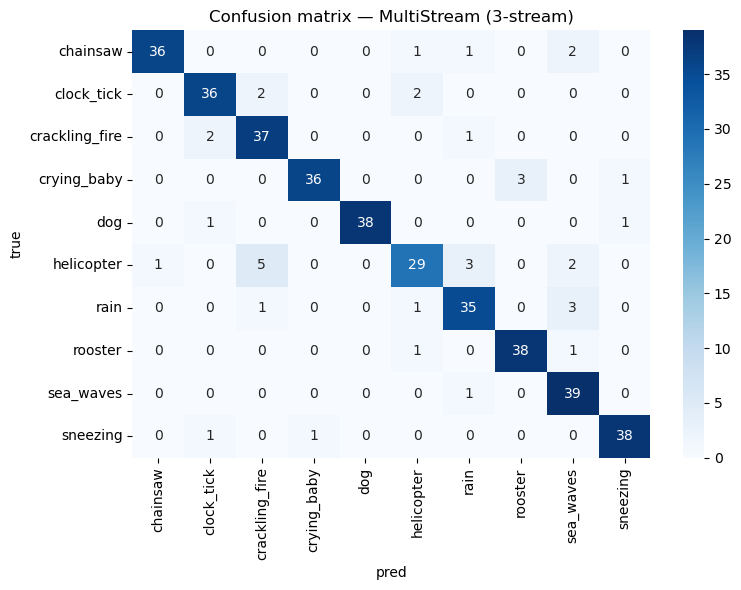

In [12]:
df = pd.DataFrame([{k: r[k] for k in ("model", "acc", "f1")} for r in results])
print("\n=== Итоговое сравнение ===")
print(df.sort_values("acc", ascending=False).to_string(index=False))

best = max(results, key=lambda r: r["acc"])
cm = confusion_matrix(best["y_true"], best["y_pred"])
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.ylabel("true"); plt.xlabel("pred")
plt.title(f"Confusion matrix — {best['model']}")
plt.tight_layout(); plt.show()

In [13]:
# Заменяет старую spec_augment_batch
def spec_augment_batch(x, fill=0.0, n_time=24, n_freq=10):
    """x: (B, C, T, F). Время — dim 2, частота — dim 3."""
    if x.dim() != 4:
        return x
    B, C, T, F = x.shape
    x = x.clone()
    for b in range(B):
        if T > n_time:
            t0 = torch.randint(0, T - n_time, (1,)).item()
            x[b, :, t0:t0+n_time, :] = fill          # маска по времени
        if F > n_freq:
            f0 = torch.randint(0, F - n_freq, (1,)).item()
            x[b, :, :, f0:f0+n_freq] = fill          # маска по частоте
    return x


def random_crop_time(x, crop_size):
    """x: (B, C, T, F). Случайное окно длины crop_size вдоль T."""
    T = x.shape[2]
    if crop_size >= T:
        return x
    start = torch.randint(0, T - crop_size + 1, (1,)).item()
    return x[:, :, start:start+crop_size, :]


def mixup_batch(x, y, alpha=0.4, n_classes=10):
    """Возвращает (mixed_x, soft_target)."""
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    B = x.size(0)
    idx = torch.randperm(B, device=x.device)
    mixed_x = lam * x + (1 - lam) * x[idx]
    y_oh = torch.zeros(B, n_classes, device=x.device)
    y_oh.scatter_(1, y.view(-1, 1), 1.0)
    mixed_y = lam * y_oh + (1 - lam) * y_oh[idx]
    return mixed_x, mixed_y


def predict_probs(model, X, batch_size=64):
    """Возвращает вероятности (не argmax) — нужно для decision fusion."""
    model.eval()
    loader = DataLoader(AudioDataset(X, np.zeros(len(X), dtype=np.int64)),
                        batch_size=batch_size, shuffle=False)
    out = []
    with torch.no_grad():
        for Xb, _ in loader:
            out.append(torch.softmax(model(Xb.to(device)), dim=1).cpu().numpy())
    return np.concatenate(out)

In [14]:
def train_cnn_fold_v2(model, Xtr, ytr, Xte, yte,
                      epochs=150, batch_size=16, lr=5e-4,
                      patience=25, crop_size=180, mixup_alpha=0.4,
                      fold_tag=""):
    tr_loader = DataLoader(AudioDataset(Xtr, ytr), batch_size=batch_size,
                           shuffle=True, pin_memory=(device.type == "cuda"))
    te_loader = DataLoader(AudioDataset(Xte, yte), batch_size=64,
                           shuffle=False, pin_memory=(device.type == "cuda"))
    model     = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=8, min_lr=1e-5)
    use_mixup = mixup_alpha and mixup_alpha > 0
    criterion = nn.BCEWithLogitsLoss() if use_mixup else nn.CrossEntropyLoss()

    best_acc, best_state, no_improve = 0.0, None, 0
    for _ in tqdm(range(epochs), desc=f"  {fold_tag}", leave=False):
        model.train()
        for X, y in tr_loader:
            X, y = X.to(device), y.to(device)
            if crop_size and crop_size < X.shape[2]:
                X = random_crop_time(X, crop_size)
            X = spec_augment_batch(X)
            if use_mixup:
                X, y_soft = mixup_batch(X, y, alpha=mixup_alpha)
                loss = criterion(model(X), y_soft)
            else:
                loss = criterion(model(X), y)
            optimizer.zero_grad(); loss.backward(); optimizer.step()

        model.eval(); correct = total = 0
        with torch.no_grad():
            for X, y in te_loader:
                preds = model(X.to(device)).argmax(1)
                correct += (preds == y.to(device)).sum().item()
                total   += y.size(0)
        val_acc = correct / total
        scheduler.step(val_acc)
        if val_acc > best_acc:
            best_acc, no_improve = val_acc, 0
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
        else:
            no_improve += 1
            if no_improve >= patience:
                break
    model.load_state_dict(best_state)
    return model


def train_multistream_fold_v2(model, Xtr_dict, ytr, Xte_dict, yte,
                              epochs=150, batch_size=16, lr=4e-4,
                              patience=28, crop_size=180, mixup_alpha=0.3,
                              fold_tag=""):
    tr_loader = DataLoader(MultiStreamDataset(Xtr_dict, ytr), batch_size=batch_size,
                           shuffle=True, pin_memory=(device.type == "cuda"))
    te_loader = DataLoader(MultiStreamDataset(Xte_dict, yte), batch_size=64,
                           shuffle=False, pin_memory=(device.type == "cuda"))
    model     = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=8, min_lr=1e-5)
    use_mixup = mixup_alpha and mixup_alpha > 0
    criterion = nn.BCEWithLogitsLoss() if use_mixup else nn.CrossEntropyLoss()

    best_acc, best_state, no_improve = 0.0, None, 0
    for _ in tqdm(range(epochs), desc=f"  {fold_tag}", leave=False):
        model.train()
        for (mel, cqt, pcen), y in tr_loader:
            mel, cqt, pcen, y = (mel.to(device), cqt.to(device),
                                 pcen.to(device), y.to(device))
            if crop_size and crop_size < mel.shape[2]:
                mel  = random_crop_time(mel,  crop_size)
                cqt  = random_crop_time(cqt,  crop_size)
                pcen = random_crop_time(pcen, crop_size)
            mel  = spec_augment_batch(mel)
            cqt  = spec_augment_batch(cqt)
            pcen = spec_augment_batch(pcen)

            if use_mixup:
                lam = np.random.beta(mixup_alpha, mixup_alpha)
                idx = torch.randperm(mel.size(0), device=mel.device)
                mel  = lam * mel  + (1 - lam) * mel[idx]
                cqt  = lam * cqt  + (1 - lam) * cqt[idx]
                pcen = lam * pcen + (1 - lam) * pcen[idx]
                y_oh = torch.zeros(y.size(0), 10, device=y.device)
                y_oh.scatter_(1, y.view(-1, 1), 1.0)
                y_soft = lam * y_oh + (1 - lam) * y_oh[idx]
                loss = criterion(model(mel, cqt, pcen), y_soft)
            else:
                loss = criterion(model(mel, cqt, pcen), y)
            optimizer.zero_grad(); loss.backward(); optimizer.step()

        model.eval(); correct = total = 0
        with torch.no_grad():
            for (mel, cqt, pcen), y in te_loader:
                preds = model(mel.to(device), cqt.to(device), pcen.to(device)).argmax(1)
                correct += (preds == y.to(device)).sum().item()
                total   += y.size(0)
        val_acc = correct / total
        scheduler.step(val_acc)
        if val_acc > best_acc:
            best_acc, no_improve = val_acc, 0
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
        else:
            no_improve += 1
            if no_improve >= patience:
                break
    model.load_state_dict(best_state)
    return model

In [15]:
def run_three_single_cnns(X_mel, X_cqt, X_pcen, y):
    """Обучает по одной CNN на каждое представление и сохраняет вероятности."""
    streams = {"log-mel": X_mel, "cqt": X_cqt, "pcen": X_pcen}
    probs_per_stream = {k: [] for k in streams}
    y_true_per_fold = []

    for fold_idx, (tr, te) in tqdm(enumerate(folds, 1), total=len(folds),
                                   desc="3 single CNNs", position=0):
        y_true_per_fold.extend(y[te])
        for name, X in streams.items():
            model = train_cnn_fold_v2(CNN(), X[tr], y[tr], X[te], y[te],
                                      epochs=150, fold_tag=f"{name} f{fold_idx}")
            probs_per_stream[name].extend(predict_probs(model, X[te]))

    y_true = np.array(y_true_per_fold)
    for name in streams:
        preds = np.argmax(np.array(probs_per_stream[name]), axis=1)
        evaluate(y_true, preds, f"CNN + {name} (v2)")

    return y_true, {k: np.array(v) for k, v in probs_per_stream.items()}


y_true_v2, probs_by_stream = run_three_single_cnns(X_mel, X_cqt, X_pcen, y_all)

3 single CNNs:   0%|          | 0/5 [00:00<?, ?it/s]

  log-mel f1:   0%|          | 0/150 [00:00<?, ?it/s]

  cqt f1:   0%|          | 0/150 [00:00<?, ?it/s]

  pcen f1:   0%|          | 0/150 [00:00<?, ?it/s]

  log-mel f2:   0%|          | 0/150 [00:00<?, ?it/s]

  cqt f2:   0%|          | 0/150 [00:00<?, ?it/s]

... (7 outputs left out)

  log-mel f5:   0%|          | 0/150 [00:00<?, ?it/s]

  cqt f5:   0%|          | 0/150 [00:00<?, ?it/s]

  pcen f5:   0%|          | 0/150 [00:00<?, ?it/s]

CNN + log-mel (v2)                acc=0.9125  macro-F1=0.9129
CNN + cqt (v2)                    acc=0.8925  macro-F1=0.8930
CNN + pcen (v2)                   acc=0.9075  macro-F1=0.9070


In [16]:
def run_multistream_v2(X_mel, X_cqt, X_pcen, y):
    all_true, all_pred = [], []
    for fold_idx, (tr, te) in tqdm(enumerate(folds, 1), total=len(folds),
                                   desc="MultiStream v2", position=0):
        Xtr = {"mel": X_mel[tr], "cqt": X_cqt[tr], "pcen": X_pcen[tr]}
        Xte = {"mel": X_mel[te], "cqt": X_cqt[te], "pcen": X_pcen[te]}
        model = train_multistream_fold_v2(MultiStreamCNN(), Xtr, y[tr],
                                          Xte, y[te], fold_tag=f"f{fold_idx}")
        # пофолдовое предсказание с вероятностями
        loader = DataLoader(MultiStreamDataset(Xte, y[te]),
                            batch_size=64, shuffle=False)
        preds = []
        model.eval()
        with torch.no_grad():
            for (mel, cqt, pcen), _ in loader:
                preds.append(model(mel.to(device), cqt.to(device),
                                   pcen.to(device)).argmax(1).cpu().numpy())
        all_true.extend(y[te]); all_pred.extend(np.concatenate(preds))
    return evaluate(all_true, all_pred, "MultiStream (3-stream, v2)")


run_multistream_v2(X_mel, X_cqt, X_pcen, y_all)

MultiStream v2:   0%|          | 0/5 [00:00<?, ?it/s]

  f1:   0%|          | 0/150 [00:00<?, ?it/s]

  f2:   0%|          | 0/150 [00:00<?, ?it/s]

  f3:   0%|          | 0/150 [00:00<?, ?it/s]

  f4:   0%|          | 0/150 [00:00<?, ?it/s]

  f5:   0%|          | 0/150 [00:00<?, ?it/s]

MultiStream (3-stream, v2)        acc=0.9075  macro-F1=0.9073


{'model': 'MultiStream (3-stream, v2)',
 'acc': 0.9075,
 'f1': 0.9072826245920153,
 'y_true': array([4, 4, 0, 2, 5, 5, 5, 5, 5, 5, 6, 2, 2, 2, 2, 5, 5, 3, 0, 0, 0, 3,
        3, 3, 6, 1, 1, 3, 3, 9, 6, 7, 7, 8, 8, 6, 9, 4, 4, 9, 4, 7, 7, 1,
        8, 8, 7, 7, 2, 1, 7, 8, 7, 2, 0, 0, 9, 9, 1, 6, 9, 6, 6, 1, 9, 4,
        3, 3, 8, 1, 1, 6, 0, 0, 2, 9, 4, 8, 8, 4, 7, 6, 8, 3, 3, 9, 4, 4,
        4, 4, 6, 4, 9, 4, 9, 1, 4, 4, 8, 8, 1, 9, 9, 9, 1, 8, 8, 8, 1, 1,
        8, 1, 1, 3, 8, 2, 2, 5, 5, 5, 5, 2, 2, 2, 2, 5, 5, 5, 5, 3, 3, 0,
        0, 0, 0, 2, 2, 7, 3, 3, 0, 0, 7, 6, 6, 6, 0, 0, 3, 7, 6, 6, 9, 6,
        1, 9, 7, 7, 7, 7, 2, 2, 7, 7, 0, 0, 0, 0, 0, 0, 0, 2, 6, 7, 4, 7,
        6, 9, 6, 6, 1, 9, 9, 9, 6, 1, 4, 9, 8, 8, 7, 2, 2, 9, 7, 9, 1, 5,
        5, 5, 3, 3, 3, 3, 3, 3, 3, 3, 5, 5, 7, 4, 8, 8, 9, 6, 2, 6, 6, 4,
        2, 7, 4, 8, 8, 1, 0, 8, 4, 1, 1, 1, 1, 4, 4, 8, 2, 5, 5, 5, 5, 0,
        0, 9, 9, 9, 0, 0, 6, 6, 5, 5, 6, 7, 7, 7, 7, 6, 2, 2, 7, 0, 0, 6,
        8, 8, 8, 3,

DecisionFusion (avg probs)        acc=0.9125  macro-F1=0.9126
DecisionFusion (geo mean)         acc=0.9025  macro-F1=0.9024

=== Итоговое сравнение (все прогоны) ===
                      model    acc       f1
 DecisionFusion (avg probs) 0.9125 0.912646
         CNN + log-mel (v2) 0.9125 0.912931
 MultiStream (3-stream, v2) 0.9075 0.907283
            CNN + pcen (v2) 0.9075 0.906953
     MultiStream (3-stream) 0.9050 0.904788
  DecisionFusion (geo mean) 0.9025 0.902422
      CNN + log-mel (filt.) 0.9000 0.899841
          CNN + CQT (filt.) 0.8925 0.892463
             CNN + cqt (v2) 0.8925 0.893014
     CNN + PCEN-mel (filt.) 0.8925 0.892629
      LogReg + MFCC (filt.) 0.8475 0.847306
RandomForest + MFCC (filt.) 0.8350 0.834233
     SVM-RBF + MFCC (filt.) 0.8250 0.825114
  BiLSTM + MFCC-seq (filt.) 0.7925 0.791316


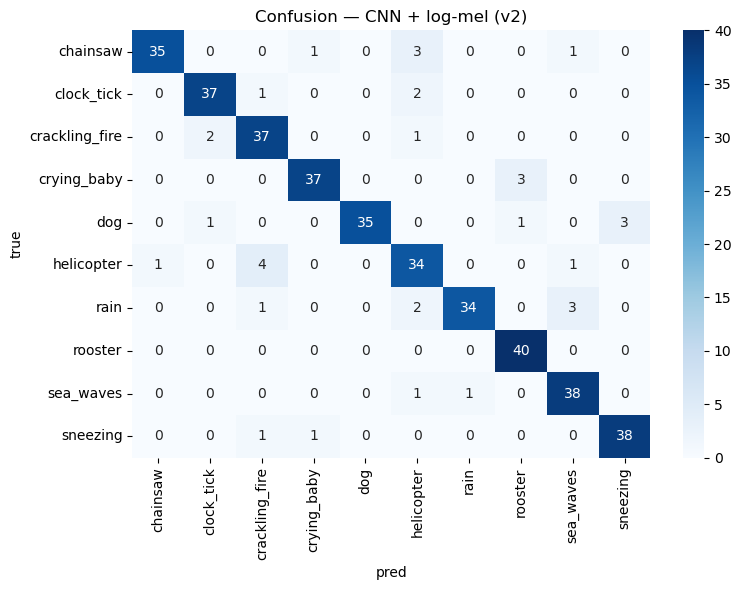

In [17]:
# Усреднение вероятностей трёх одиночных CNN
probs_avg = sum(probs_by_stream.values()) / len(probs_by_stream)
preds_fusion = probs_avg.argmax(axis=1)
evaluate(y_true_v2, preds_fusion, "DecisionFusion (avg probs)")

# Геометрическое среднее как альтернатива
log_p = sum(np.log(p + 1e-8) for p in probs_by_stream.values()) / len(probs_by_stream)
preds_geo = log_p.argmax(axis=1)
evaluate(y_true_v2, preds_geo, "DecisionFusion (geo mean)")

# Итоговая таблица по всем прогонам
df = pd.DataFrame([{k: r[k] for k in ("model", "acc", "f1")} for r in results])
print("\n=== Итоговое сравнение (все прогоны) ===")
print(df.sort_values("acc", ascending=False).to_string(index=False))

best = max(results, key=lambda r: r["acc"])
cm = confusion_matrix(best["y_true"], best["y_pred"])
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.ylabel("true"); plt.xlabel("pred")
plt.title(f"Confusion — {best['model']}")
plt.tight_layout(); plt.show()

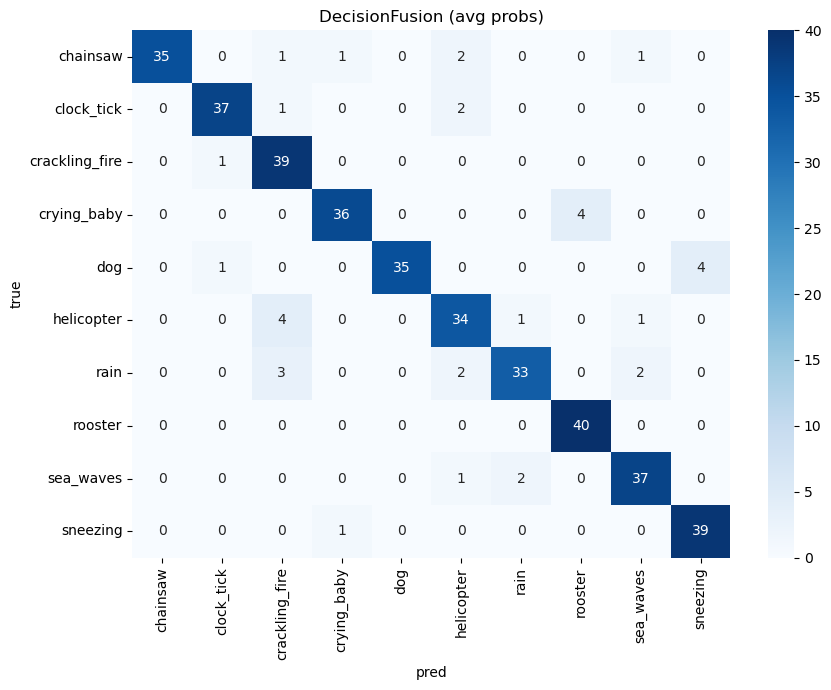


Топ-10 путаниц (истина → предсказание):
   4  helicopter      → crackling_fire
   4  dog             → sneezing
   4  crying_baby     → rooster
   3  rain            → crackling_fire
   2  sea_waves       → rain
   2  rain            → sea_waves
   2  rain            → helicopter
   2  clock_tick      → helicopter
   2  chainsaw        → helicopter
   1  sneezing        → crying_baby


In [18]:
best_name = "DecisionFusion (avg probs)"
best = next(r for r in results if r["model"] == best_name)
cm = confusion_matrix(best["y_true"], best["y_pred"])

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.ylabel("true"); plt.xlabel("pred")
plt.title(best_name)
plt.tight_layout(); plt.show()

pairs = [(cm[i, j], classes[i], classes[j])
         for i in range(10) for j in range(10) if i != j and cm[i, j] > 0]
pairs.sort(reverse=True)
print("\nТоп-10 путаниц (истина → предсказание):")
for n, a, b in pairs[:10]:
    print(f"  {n:2d}  {a:15s} → {b}")

In [19]:
def logmel_no_filter(path):
    y, _ = librosa.load(path, sr=SR)
    y = trim_silence(y)
    S = librosa.feature.melspectrogram(y=y, sr=SR, n_mels=N_MELS,
                                        n_fft=N_FFT, hop_length=HOP)
    S = librosa.power_to_db(S, ref=np.max)
    S = _pad_or_crop(S, fill=S.min())
    return S.T

print("Извлекаем log-mel без фильтров...")
X_mel_nf = normalize_spec_4d(stack_3d(logmel_no_filter, "  log-mel-nf"))
print(f"  {X_mel_nf.shape}")

# Тот же v2-пайплайн (mixup + crop), только на X_mel_nf
y_true_nf, probs_nf = [], []
for fold_idx, (tr, te) in tqdm(enumerate(folds, 1), total=len(folds),
                                desc="CNN log-mel (NO filter, v2)", position=0):
    model = train_cnn_fold_v2(CNN(), X_mel_nf[tr], y_all[tr],
                              X_mel_nf[te], y_all[te],
                              epochs=150, fold_tag=f"f{fold_idx}")
    y_true_nf.extend(y_all[te])
    probs_nf.extend(predict_probs(model, X_mel_nf[te]))

y_true_nf = np.array(y_true_nf); probs_nf = np.array(probs_nf)
evaluate(y_true_nf, probs_nf.argmax(1), "CNN + log-mel (NO filter, v2)")

# Сравнение с "с фильтрами" из предыдущего прогона
print("\nСравнение фильтров для CNN + log-mel (v2):")
for r in results:
    if "log-mel" in r["model"] and "v2" in r["model"]:
        print(f"  {r['model']:35s}  acc={r['acc']:.4f}")

Извлекаем log-mel без фильтров...


  log-mel-nf:   0%|          | 0/400 [00:00<?, ?it/s]

  (400, 1, 216, 128)


CNN log-mel (NO filter, v2):   0%|          | 0/5 [00:00<?, ?it/s]

  f1:   0%|          | 0/150 [00:00<?, ?it/s]

  f2:   0%|          | 0/150 [00:00<?, ?it/s]

  f3:   0%|          | 0/150 [00:00<?, ?it/s]

  f4:   0%|          | 0/150 [00:00<?, ?it/s]

  f5:   0%|          | 0/150 [00:00<?, ?it/s]

CNN + log-mel (NO filter, v2)     acc=0.9000  macro-F1=0.8999

Сравнение фильтров для CNN + log-mel (v2):
  CNN + log-mel (v2)                   acc=0.9125
  CNN + log-mel (NO filter, v2)        acc=0.9000


In [20]:
def set_seed_full(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def run_seed_ensemble_single(X, y, name, n_seeds=3, epochs=150):
    """n_seeds обучений на fold; усредняем probabilities."""
    all_true, all_probs = [], []
    for fold_idx, (tr, te) in tqdm(enumerate(folds, 1), total=len(folds),
                                    desc=f"{name} folds", position=0):
        seed_probs = []
        for s in range(n_seeds):
            set_seed_full(SEED + 100 * fold_idx + s)
            model = train_cnn_fold_v2(
                CNN(), X[tr], y[tr], X[te], y[te], epochs=epochs,
                fold_tag=f"f{fold_idx} s{s+1}/{n_seeds}")
            seed_probs.append(predict_probs(model, X[te]))
        all_probs.append(np.mean(seed_probs, axis=0))
        all_true.append(y[te])
    y_true = np.concatenate(all_true)
    probs  = np.concatenate(all_probs)
    return evaluate(y_true, probs.argmax(1), name), probs, y_true


res_ens_mel, probs_ens_mel, y_true_ens = run_seed_ensemble_single(
    X_mel, y_all, "CNN log-mel ×3 seeds", n_seeds=3)

CNN log-mel ×3 seeds folds:   0%|          | 0/5 [00:00<?, ?it/s]

  f1 s1/3:   0%|          | 0/150 [00:00<?, ?it/s]

  f1 s2/3:   0%|          | 0/150 [00:00<?, ?it/s]

  f1 s3/3:   0%|          | 0/150 [00:00<?, ?it/s]

  f2 s1/3:   0%|          | 0/150 [00:00<?, ?it/s]

  f2 s2/3:   0%|          | 0/150 [00:00<?, ?it/s]

... (7 outputs left out)

  f5 s1/3:   0%|          | 0/150 [00:00<?, ?it/s]

  f5 s2/3:   0%|          | 0/150 [00:00<?, ?it/s]

  f5 s3/3:   0%|          | 0/150 [00:00<?, ?it/s]

CNN log-mel ×3 seeds              acc=0.9050  macro-F1=0.9052


In [21]:
res_ens_pcen, probs_ens_pcen, _ = run_seed_ensemble_single(
    X_pcen, y_all, "CNN pcen ×3 seeds", n_seeds=3)
res_ens_cqt, probs_ens_cqt, _ = run_seed_ensemble_single(
    X_cqt, y_all, "CNN cqt ×3 seeds", n_seeds=3)

# Финальный fusion
probs_final = (probs_ens_mel + probs_ens_pcen + probs_ens_cqt) / 3
evaluate(y_true_ens, probs_final.argmax(1), "3-seeds × 3-streams (avg)")

# Финальная сводка
df = pd.DataFrame([{k: r[k] for k in ("model", "acc", "f1")} for r in results])
print("\n=== Итог ===")
print(df.sort_values("acc", ascending=False).to_string(index=False))

CNN pcen ×3 seeds folds:   0%|          | 0/5 [00:00<?, ?it/s]

  f1 s1/3:   0%|          | 0/150 [00:00<?, ?it/s]

  f1 s2/3:   0%|          | 0/150 [00:00<?, ?it/s]

  f1 s3/3:   0%|          | 0/150 [00:00<?, ?it/s]

  f2 s1/3:   0%|          | 0/150 [00:00<?, ?it/s]

  f2 s2/3:   0%|          | 0/150 [00:00<?, ?it/s]

... (24 outputs left out)

  f5 s1/3:   0%|          | 0/150 [00:00<?, ?it/s]

  f5 s2/3:   0%|          | 0/150 [00:00<?, ?it/s]

  f5 s3/3:   0%|          | 0/150 [00:00<?, ?it/s]

CNN cqt ×3 seeds                  acc=0.8975  macro-F1=0.8982
3-seeds × 3-streams (avg)         acc=0.9075  macro-F1=0.9077

=== Итог ===
                        model    acc       f1
           CNN + log-mel (v2) 0.9125 0.912931
   DecisionFusion (avg probs) 0.9125 0.912646
   MultiStream (3-stream, v2) 0.9075 0.907283
    3-seeds × 3-streams (avg) 0.9075 0.907721
              CNN + pcen (v2) 0.9075 0.906953
       MultiStream (3-stream) 0.9050 0.904788
         CNN log-mel ×3 seeds 0.9050 0.905225
    DecisionFusion (geo mean) 0.9025 0.902422
            CNN pcen ×3 seeds 0.9025 0.902755
CNN + log-mel (NO filter, v2) 0.9000 0.899927
        CNN + log-mel (filt.) 0.9000 0.899841
             CNN cqt ×3 seeds 0.8975 0.898217
       CNN + PCEN-mel (filt.) 0.8925 0.892629
            CNN + CQT (filt.) 0.8925 0.892463
               CNN + cqt (v2) 0.8925 0.893014
        LogReg + MFCC (filt.) 0.8475 0.847306
  RandomForest + MFCC (filt.) 0.8350 0.834233
       SVM-RBF + MFCC (filt.) 0.82

In [22]:
def augment_audio(y, sr=SR, rate_range=(0.9, 1.1), pitch_steps=(-2, 2)):
    if np.random.rand() < 0.5:
        y = librosa.effects.time_stretch(y, rate=np.random.uniform(*rate_range))
    else:
        y = librosa.effects.pitch_shift(y, sr=sr,
                                        n_steps=np.random.uniform(*pitch_steps))
    return y


def logmel_aug(path):
    y, _ = librosa.load(path, sr=SR)
    y = apply_preprocessing(y)
    y = trim_silence(y)
    y = augment_audio(y)
    S = librosa.feature.melspectrogram(y=y, sr=SR, n_mels=N_MELS,
                                        n_fft=N_FFT, hop_length=HOP)
    S = librosa.power_to_db(S, ref=np.max)
    S = _pad_or_crop(S, fill=S.min())
    return S.T


def run_on_custom_folds(X, y, folds_list, name, epochs=150):
    """Как run_single_stream_cnn, но принимает folds снаружи."""
    all_true, all_pred = [], []
    for fold_idx, (tr, te) in tqdm(enumerate(folds_list, 1),
                                   total=len(folds_list),
                                   desc=name, position=0):
        model = train_cnn_fold_v2(CNN(), X[tr], y[tr], X[te], y[te],
                                  epochs=epochs, fold_tag=f"f{fold_idx}")
        all_true.extend(y[te]); all_pred.extend(predict_nn(model, X[te]))
    return evaluate(all_true, all_pred, name)


# Извлекаем одну аугментированную копию
set_seed_full(SEED + 777)
print("Извлекаем аугментированные log-mel...")
X_mel_aug = normalize_spec_4d(stack_3d(logmel_aug, "  log-mel-aug"))

# Датасет 2x: оригиналы + аугментации
X_mel_2x = np.concatenate([X_mel, X_mel_aug], axis=0)
y_all_2x = np.concatenate([y_all, y_all], axis=0)
folds_2x = [(np.concatenate([tr, tr + len(X_mel)]), te)
            for tr, te in folds]

run_on_custom_folds(X_mel_2x, y_all_2x, folds_2x, "CNN log-mel 2x-aug")

Извлекаем аугментированные log-mel...


  log-mel-aug:   0%|          | 0/400 [00:00<?, ?it/s]

CNN log-mel 2x-aug:   0%|          | 0/5 [00:00<?, ?it/s]

  f1:   0%|          | 0/150 [00:00<?, ?it/s]

  f2:   0%|          | 0/150 [00:00<?, ?it/s]

  f3:   0%|          | 0/150 [00:00<?, ?it/s]

  f4:   0%|          | 0/150 [00:00<?, ?it/s]

  f5:   0%|          | 0/150 [00:00<?, ?it/s]

CNN log-mel 2x-aug                acc=0.9150  macro-F1=0.9152


{'model': 'CNN log-mel 2x-aug',
 'acc': 0.915,
 'f1': 0.9152461086565926,
 'y_true': array([4, 4, 0, 2, 5, 5, 5, 5, 5, 5, 6, 2, 2, 2, 2, 5, 5, 3, 0, 0, 0, 3,
        3, 3, 6, 1, 1, 3, 3, 9, 6, 7, 7, 8, 8, 6, 9, 4, 4, 9, 4, 7, 7, 1,
        8, 8, 7, 7, 2, 1, 7, 8, 7, 2, 0, 0, 9, 9, 1, 6, 9, 6, 6, 1, 9, 4,
        3, 3, 8, 1, 1, 6, 0, 0, 2, 9, 4, 8, 8, 4, 7, 6, 8, 3, 3, 9, 4, 4,
        4, 4, 6, 4, 9, 4, 9, 1, 4, 4, 8, 8, 1, 9, 9, 9, 1, 8, 8, 8, 1, 1,
        8, 1, 1, 3, 8, 2, 2, 5, 5, 5, 5, 2, 2, 2, 2, 5, 5, 5, 5, 3, 3, 0,
        0, 0, 0, 2, 2, 7, 3, 3, 0, 0, 7, 6, 6, 6, 0, 0, 3, 7, 6, 6, 9, 6,
        1, 9, 7, 7, 7, 7, 2, 2, 7, 7, 0, 0, 0, 0, 0, 0, 0, 2, 6, 7, 4, 7,
        6, 9, 6, 6, 1, 9, 9, 9, 6, 1, 4, 9, 8, 8, 7, 2, 2, 9, 7, 9, 1, 5,
        5, 5, 3, 3, 3, 3, 3, 3, 3, 3, 5, 5, 7, 4, 8, 8, 9, 6, 2, 6, 6, 4,
        2, 7, 4, 8, 8, 1, 0, 8, 4, 1, 1, 1, 1, 4, 4, 8, 2, 5, 5, 5, 5, 0,
        0, 9, 9, 9, 0, 0, 6, 6, 5, 5, 6, 7, 7, 7, 7, 6, 2, 2, 7, 0, 0, 6,
        8, 8, 8, 3, 3, 3, 9,

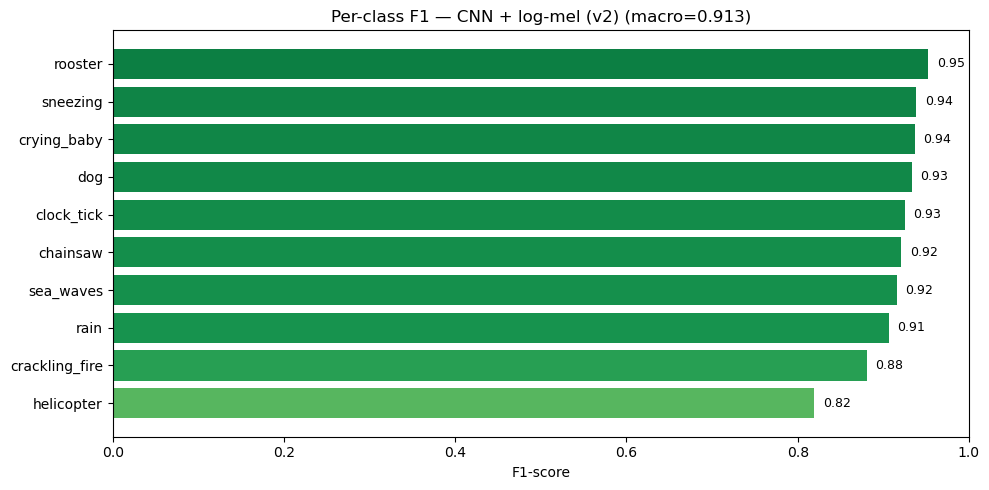


Слабые классы (F1 < 0.85):
     class  precision  recall       f1  support
helicopter   0.790698    0.85 0.819277     40.0


In [23]:
from sklearn.metrics import classification_report

best_name = "CNN + log-mel (v2)"
best = next(r for r in results if r["model"] == best_name)
y_true, y_pred = best["y_true"], best["y_pred"]

# --- Per-class F1 ---
report = classification_report(y_true, y_pred, target_names=classes, output_dict=True)
per_class = pd.DataFrame({
    "class": classes,
    "precision": [report[c]["precision"] for c in classes],
    "recall":    [report[c]["recall"]    for c in classes],
    "f1":        [report[c]["f1-score"]  for c in classes],
    "support":   [report[c]["support"]   for c in classes],
}).sort_values("f1", ascending=True)

fig, ax = plt.subplots(figsize=(10, 5))
colors = plt.cm.RdYlGn(per_class["f1"] / 1.0)
ax.barh(per_class["class"], per_class["f1"], color=colors)
ax.set_xlim(0, 1); ax.set_xlabel("F1-score")
ax.set_title(f"Per-class F1 — {best_name} (macro={per_class['f1'].mean():.3f})")
for i, (c, f1) in enumerate(zip(per_class["class"], per_class["f1"])):
    ax.text(f1 + 0.01, i, f"{f1:.2f}", va="center", fontsize=9)
plt.tight_layout(); plt.show()

print("\nСлабые классы (F1 < 0.85):")
print(per_class[per_class["f1"] < 0.85].to_string(index=False))

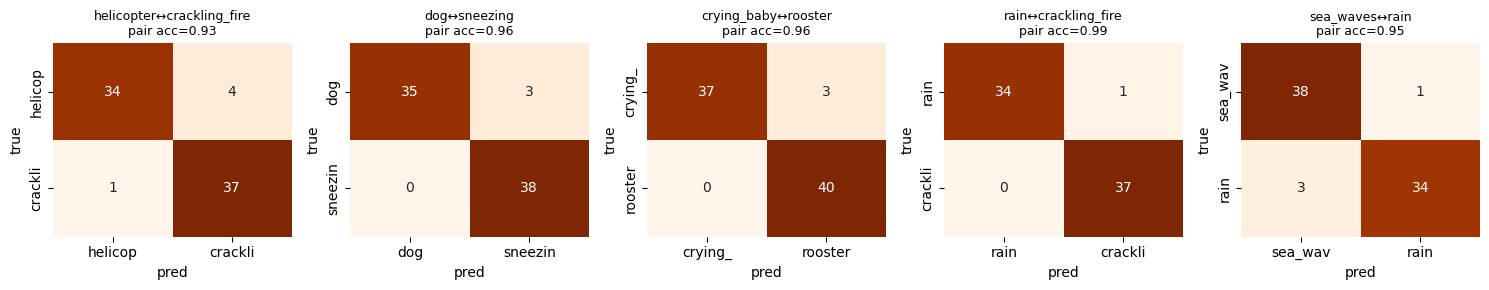

In [24]:
top_pairs = [("helicopter", "crackling_fire"),
             ("dog", "sneezing"),
             ("crying_baby", "rooster"),
             ("rain", "crackling_fire"),
             ("sea_waves", "rain")]

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, (a, b) in zip(axes, top_pairs):
    ia, ib = classes.index(a), classes.index(b)
    mask = np.isin(y_true, [ia, ib])
    cm2 = confusion_matrix(y_true[mask], y_pred[mask], labels=[ia, ib])
    acc2 = np.trace(cm2) / cm2.sum()
    sns.heatmap(cm2, annot=True, fmt="d", cmap="Oranges", ax=ax, cbar=False,
                xticklabels=[a[:7], b[:7]], yticklabels=[a[:7], b[:7]])
    ax.set_title(f"{a}↔{b}\npair acc={acc2:.2f}", fontsize=9)
    ax.set_xlabel("pred"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

=== Топ-пара: helicopter vs crackling_fire ===


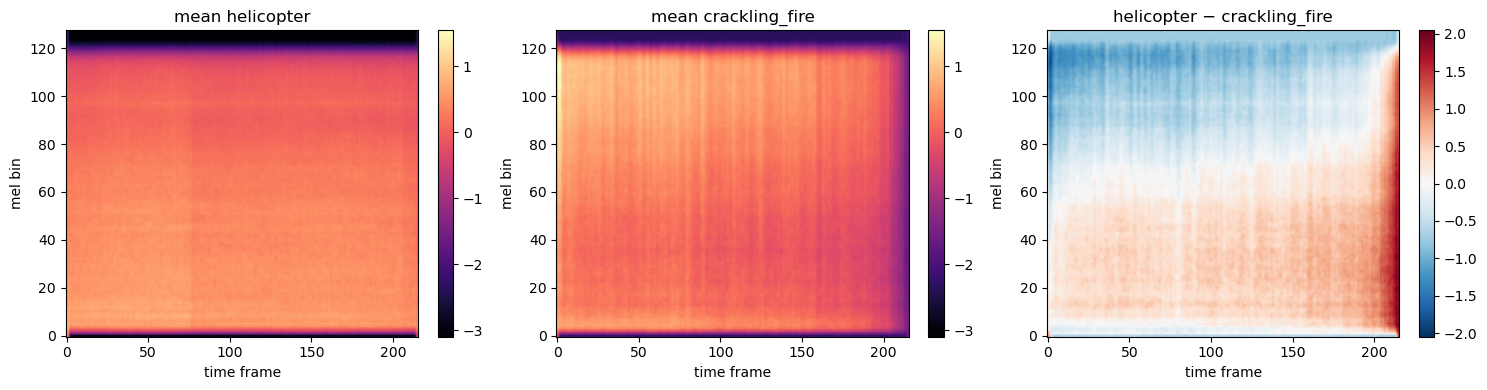


=== Вторая пара: dog vs sneezing ===


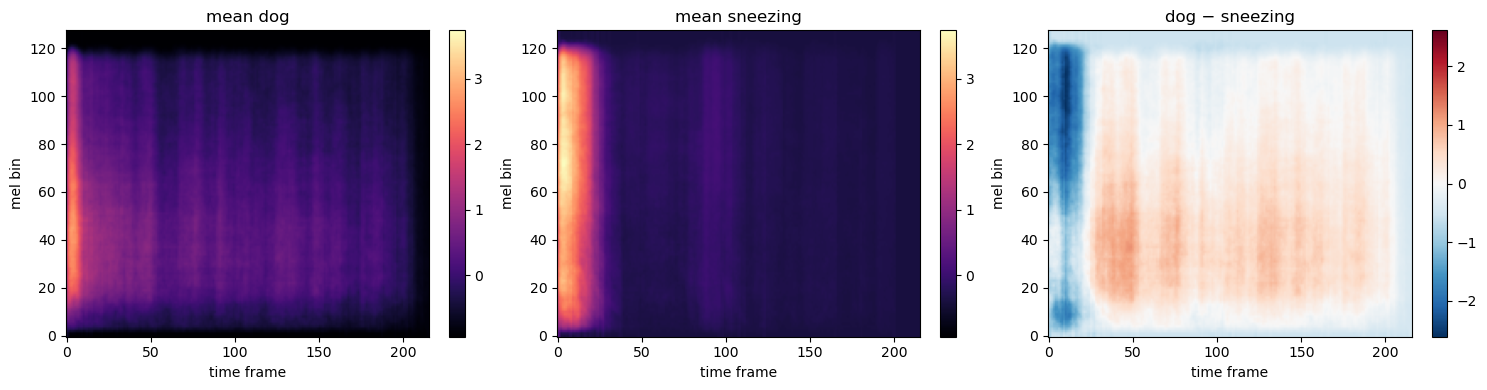

In [25]:
def mean_spec_for_class(X, y, cls_idx):
    """Усреднённая спектрограмма (dB) по всем примерам класса.
       X: (N, 1, T, F), нормализованные — восстанавливать dB не нужно,
       важна только относительная структура."""
    return X[y == cls_idx].mean(axis=0)[0]  # (T, F)


def plot_pair_difference(cls_a, cls_b, X=X_mel, y=y_all):
    ia, ib = classes.index(cls_a), classes.index(cls_b)
    mA = mean_spec_for_class(X, y, ia)
    mB = mean_spec_for_class(X, y, ib)
    diff = mA - mB

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    vmin, vmax = min(mA.min(), mB.min()), max(mA.max(), mB.max())
    for ax, (title, M, kw) in zip(axes, [
        (f"mean {cls_a}",  mA,   dict(vmin=vmin, vmax=vmax, cmap="magma")),
        (f"mean {cls_b}",  mB,   dict(vmin=vmin, vmax=vmax, cmap="magma")),
        (f"{cls_a} − {cls_b}", diff, dict(cmap="RdBu_r",
                                          vmin=-np.abs(diff).max(),
                                          vmax=np.abs(diff).max())),
    ]):
        im = ax.imshow(M.T, aspect="auto", origin="lower", **kw)
        ax.set_title(title); ax.set_xlabel("time frame"); ax.set_ylabel("mel bin")
        plt.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout(); plt.show()


print("=== Топ-пара: helicopter vs crackling_fire ===")
plot_pair_difference("helicopter", "crackling_fire")

print("\n=== Вторая пара: dog vs sneezing ===")
plot_pair_difference("dog", "sneezing")

extract embeddings:   0%|          | 0/5 [00:00<?, ?it/s]

  emb f1:   0%|          | 0/150 [00:00<?, ?it/s]

  emb f2:   0%|          | 0/150 [00:00<?, ?it/s]

  emb f3:   0%|          | 0/150 [00:00<?, ?it/s]

  emb f4:   0%|          | 0/150 [00:00<?, ?it/s]

  emb f5:   0%|          | 0/150 [00:00<?, ?it/s]

Запускаем t-SNE...


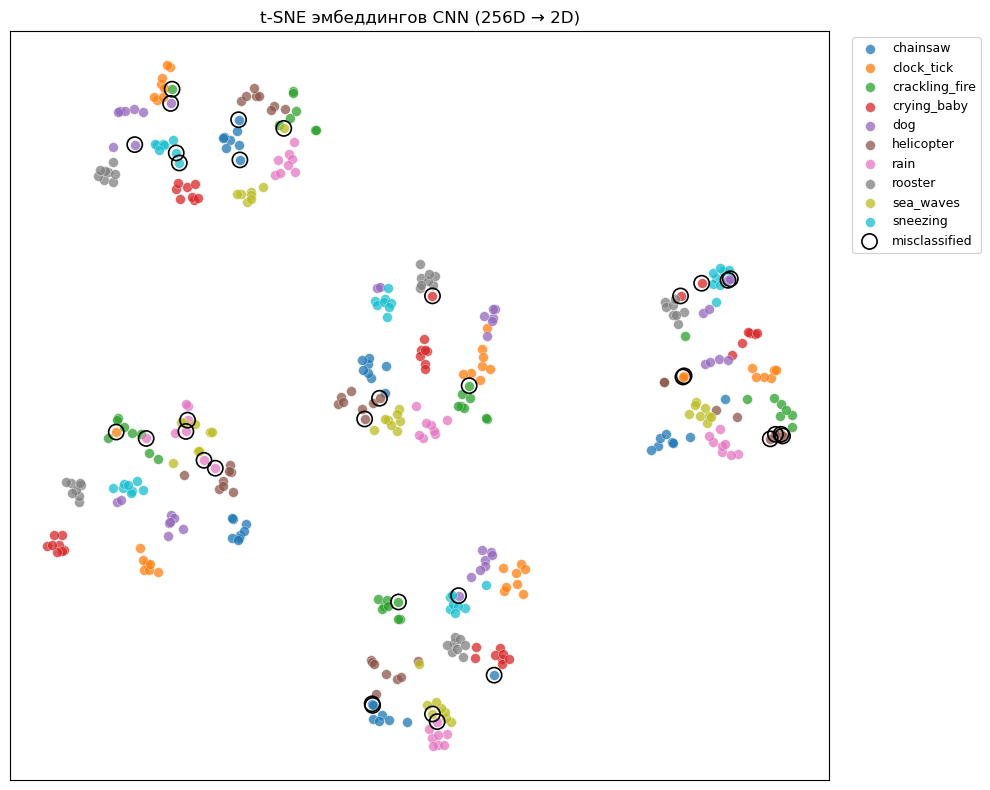

Silhouette score (256D): -0.002  (0=перекрытие, 1=идеальные кластеры)


In [26]:
from sklearn.manifold import TSNE

def extract_embedding(model, X, batch_size=64):
    """Последний слой head — Linear(256, 10). Берём выход перед ним (256-мерный)."""
    model.eval()
    loader = DataLoader(AudioDataset(X, np.zeros(len(X), dtype=np.int64)),
                        batch_size=batch_size, shuffle=False)
    # Временно режем head до предпоследнего слоя
    original_head = model.head
    model.head = nn.Sequential(*list(original_head)[:-1])  # без последнего Linear
    embs = []
    with torch.no_grad():
        for Xb, _ in loader:
            embs.append(model(Xb.to(device)).cpu().numpy())
    model.head = original_head
    return np.concatenate(embs)


# Собираем эмбеддинги по фолдам (для каждого тестового примера — из его фолда)
embeddings = np.zeros((len(y_all), 256), dtype=np.float32)
for fold_idx, (tr, te) in tqdm(enumerate(folds, 1), total=len(folds),
                                desc="extract embeddings"):
    model = train_cnn_fold_v2(CNN(), X_mel[tr], y_all[tr],
                              X_mel[te], y_all[te],
                              epochs=150, fold_tag=f"emb f{fold_idx}")
    embeddings[te] = extract_embedding(model, X_mel[te])

# t-SNE
print("Запускаем t-SNE...")
tsne = TSNE(n_components=2, perplexity=30, learning_rate="auto",
            init="pca", random_state=SEED)
emb_2d = tsne.fit_transform(embeddings)

fig, ax = plt.subplots(figsize=(10, 8))
cmap = plt.cm.tab10
for i, cls in enumerate(classes):
    mask = y_all == i
    ax.scatter(emb_2d[mask, 0], emb_2d[mask, 1], s=50, alpha=0.75,
               color=cmap(i), label=cls, edgecolors="white", linewidth=0.3)
# Отдельно — ошибочные точки поверх
wrong = y_true != y_pred
ax.scatter(emb_2d[wrong, 0], emb_2d[wrong, 1], s=120, facecolors="none",
           edgecolors="black", linewidth=1.2, label="misclassified")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
ax.set_title("t-SNE эмбеддингов CNN (256D → 2D)")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

# Количественная оценка: среднее расстояние до центроида своего класса vs чужого
from sklearn.metrics import silhouette_score
sil = silhouette_score(embeddings, y_all)
print(f"Silhouette score (256D): {sil:.3f}  (0=перекрытие, 1=идеальные кластеры)")

  gradcam model:   0%|          | 0/150 [00:00<?, ?it/s]

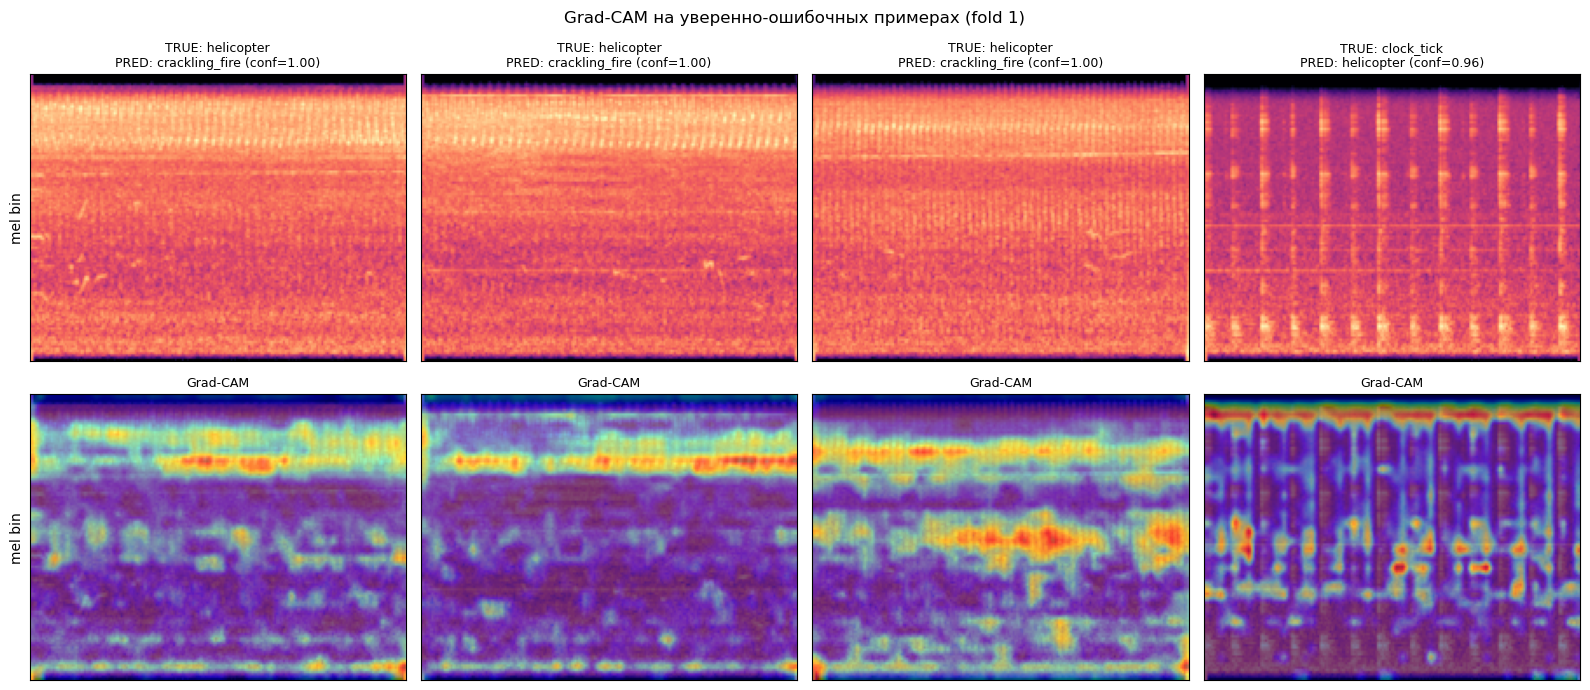

In [27]:
class GradCAM:
    """Grad-CAM для последнего Conv2d слоя. Простая реализация через хуки."""
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inp, out):
        self.activations = out.detach()

    def _save_gradient(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()

    def __call__(self, x, class_idx):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        self.model.zero_grad()
        logits[0, class_idx].backward()
        # (1, C, H, W) — веса: усредняем градиенты по H, W
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)     # (1, C, 1, 1)
        cam = (weights * self.activations).sum(dim=1, keepdim=True) # (1, 1, H, W)
        cam = torch.relu(cam)
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        # Upsample до входного разрешения
        cam = torch.nn.functional.interpolate(cam, size=x.shape[2:],
                                              mode="bilinear", align_corners=False)
        return cam[0, 0].cpu().numpy()


# Обучим одну финальную модель на всех данных (все 5 фолдов усредним через predict_probs)
# Для Grad-CAM используем fold 1 — модель, которая на нём обучена
tr, te = folds[0]
model_gc = train_cnn_fold_v2(CNN(), X_mel[tr], y_all[tr],
                             X_mel[te], y_all[te],
                             epochs=150, fold_tag="gradcam model")
preds_te = predict_nn(model_gc, X_mel[te])

# Найдём топ-4 уверенно-ошибочных примера
probs_te = predict_probs(model_gc, X_mel[te])
err_idx = np.where(preds_te != y_all[te])[0]
conf_wrong = probs_te[err_idx, preds_te[err_idx]]                # уверенность в ошибке
top_wrong = err_idx[np.argsort(-conf_wrong)[:4]]

# Достаём последний Conv2d (перед AdaptiveAvgPool2d)
target_conv = model_gc.features[7]                                # последний Conv2d
cam_engine = GradCAM(model_gc, target_conv)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for col, idx in enumerate(top_wrong):
    x = torch.from_numpy(X_mel[te][idx]).float()
    true_lbl, pred_lbl = int(y_all[te][idx]), int(preds_te[idx])
    cam = cam_engine(x, pred_lbl)                                 # GradCAM для предсказанного класса

    # Спектрограмма как «картинка»: (T, F) → транспонируем в (F, T) для imshow
    spec = x[0].numpy().T
    axes[0, col].imshow(spec, aspect="auto", origin="lower", cmap="magma")
    axes[0, col].set_title(f"TRUE: {classes[true_lbl]}\nPRED: {classes[pred_lbl]} "
                           f"(conf={conf_wrong[np.where(err_idx==idx)[0][0]]:.2f})",
                           fontsize=9)
    axes[0, col].set_xticks([]); axes[0, col].set_yticks([])

    axes[1, col].imshow(spec, aspect="auto", origin="lower", cmap="magma")
    # CAM тоже (T, F) → транспонируем; bilinear interpolate уже сделал размер как у входа (1, T, F)
    cam_disp = cam.reshape(cam.shape[0], -1).T if cam.ndim == 2 else cam.T
    axes[1, col].imshow(cam.T, aspect="auto", origin="lower", cmap="jet",
                        alpha=0.5)
    axes[1, col].set_xticks([]); axes[1, col].set_yticks([])
    axes[1, col].set_title("Grad-CAM", fontsize=9)

axes[0, 0].set_ylabel("mel bin")
axes[1, 0].set_ylabel("mel bin")
plt.suptitle("Grad-CAM на уверенно-ошибочных примерах (fold 1)", fontsize=12)
plt.tight_layout(); plt.show()

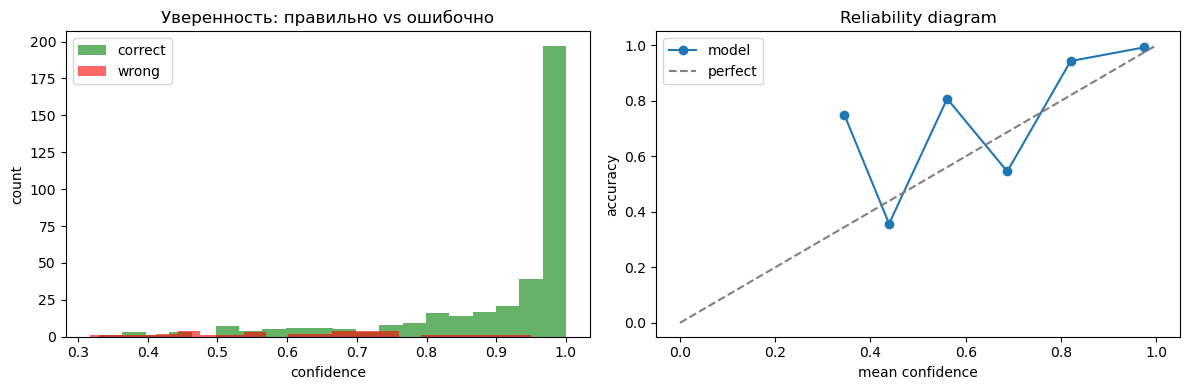

Средняя уверенность правильных: 0.903
Средняя уверенность ошибочных:  0.624


In [28]:
from sklearn.calibration import calibration_curve

# Из DecisionFusion (avg probs) — вероятности уже есть
probs_final = probs_by_stream  # словарь {stream: probs}
probs_avg = sum(probs_final.values()) / len(probs_final)
y_pred_avg = probs_avg.argmax(1)
conf = probs_avg.max(1)
correct = (y_pred_avg == y_true_v2).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 1) Гистограмма уверенности правильных и ошибочных
axes[0].hist(conf[correct == 1], bins=20, alpha=0.6, label="correct", color="green")
axes[0].hist(conf[correct == 0], bins=20, alpha=0.6, label="wrong", color="red")
axes[0].set_xlabel("confidence"); axes[0].set_ylabel("count")
axes[0].set_title("Уверенность: правильно vs ошибочно")
axes[0].legend()

# 2) Reliability diagram
prob_true, prob_pred = calibration_curve(correct, conf, n_bins=8, strategy="uniform")
axes[1].plot(prob_pred, prob_true, "o-", label="model")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="perfect")
axes[1].set_xlabel("mean confidence"); axes[1].set_ylabel("accuracy")
axes[1].set_title("Reliability diagram"); axes[1].legend()

plt.tight_layout(); plt.show()

mean_conf_wrong = conf[correct == 0].mean()
mean_conf_right = conf[correct == 1].mean()
print(f"Средняя уверенность правильных: {mean_conf_right:.3f}")
print(f"Средняя уверенность ошибочных:  {mean_conf_wrong:.3f}")